# Project: Customer Segmentation & Churn Pattern Analytics
# Organization: European Banking | Unified Mentor Internship
# Notebook: 01 - Exploratory Data Analysis
# Author: [Rishi prajapati]


## Objective
Explore the bank customer dataset, understand churn patterns,
and create customer segments for deeper analysis.

In [1]:
# ── Standard Imports ──────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import os
import warnings

warnings.filterwarnings('ignore')

# Plot settings
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size']      = 12
sns.set_style('whitegrid')
sns.set_palette('husl')

# Create figures folder if not exists
os.makedirs('../reports/figures', exist_ok=True)

print("✅ All libraries imported successfully!")

✅ All libraries imported successfully!


In [2]:
# ── Load Dataset ──────────────────────────────────────────────────
df = pd.read_csv('../data/raw/Churn_Modelling.csv')

print("=" * 55)
print(f"  Dataset Shape   : {df.shape[0]} rows × {df.shape[1]} columns")
print(f"  Churn Rate      : {df['Exited'].mean():.2%}")
print(f"  Total Churned   : {df['Exited'].sum()} customers")
print(f"  Total Retained  : {(df['Exited'] == 0).sum()} customers")
print("=" * 55)
print(f"\nColumn Names:\n{df.columns.tolist()}")

  Dataset Shape   : 10000 rows × 14 columns
  Churn Rate      : 20.37%
  Total Churned   : 2037 customers
  Total Retained  : 7963 customers

Column Names:
['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


In [3]:
# ── First Look at Data ────────────────────────────────────────────
df.head(10)

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
5,6,15574012,Chu,645,Spain,Male,44,8,113755.78,2,1,0,149756.71,1
6,7,15592531,Bartlett,822,France,Male,50,7,0.00,2,1,1,10062.80,0
7,8,15656148,Obinna,376,Germany,Female,29,4,115046.74,4,1,0,119346.88,1
8,9,15792365,He,501,France,Male,44,4,142051.07,2,0,1,74940.50,0
9,10,15592389,H?,684,France,Male,27,2,134603.88,1,1,1,71725.73,0


In [4]:
# ── Data Types & Missing Values ───────────────────────────────────
print("📋 Data Types:")
print(df.dtypes)
print("\n🔍 Missing Values:")
print(df.isnull().sum())
print("\n📊 Basic Statistics:")
df.describe().round(2)

📋 Data Types:
RowNumber            int64
CustomerId           int64
Surname             object
CreditScore          int64
Geography           object
Gender              object
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object

🔍 Missing Values:
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

📊 Basic Statistics:


,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.0
mean,5000.50,15690940.57,650.53,38.92,5.01,76485.89,1.53,0.71,0.52,100090.24,0.2
std,2886.90,71936.19,96.65,10.49,2.89,62397.41,0.58,0.46,0.50,57510.49,0.4
min,1.00,15565701.00,350.00,18.00,0.00,0.00,1.00,0.00,0.00,11.58,0.0
25%,2500.75,15628528.25,584.00,32.00,3.00,0.00,1.00,0.00,0.00,51002.11,0.0
50%,5000.50,15690738.00,652.00,37.00,5.00,97198.54,1.00,1.00,1.00,100193.92,0.0
75%,7500.25,15753233.75,718.00,44.00,7.00,127644.24,2.00,1.00,1.00,149388.25,0.0
max,10000.00,15815690.00,850.00,92.00,10.00,250898.09,4.00,1.00,1.00,199992.48,1.0


In [5]:
# ── Remove Non-analytical Columns ────────────────────────────────
# Surname & RowNumber & CustomerId are not useful for analysis
cols_to_drop = ['RowNumber', 'CustomerId', 'Surname']
df.drop(columns=cols_to_drop, inplace=True)

print(f"✅ Dropped columns: {cols_to_drop}")
print(f"   Remaining columns: {df.columns.tolist()}")
print(f"   New shape: {df.shape}")

✅ Dropped columns: ['RowNumber', 'CustomerId', 'Surname']
   Remaining columns: ['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']
   New shape: (10000, 11)


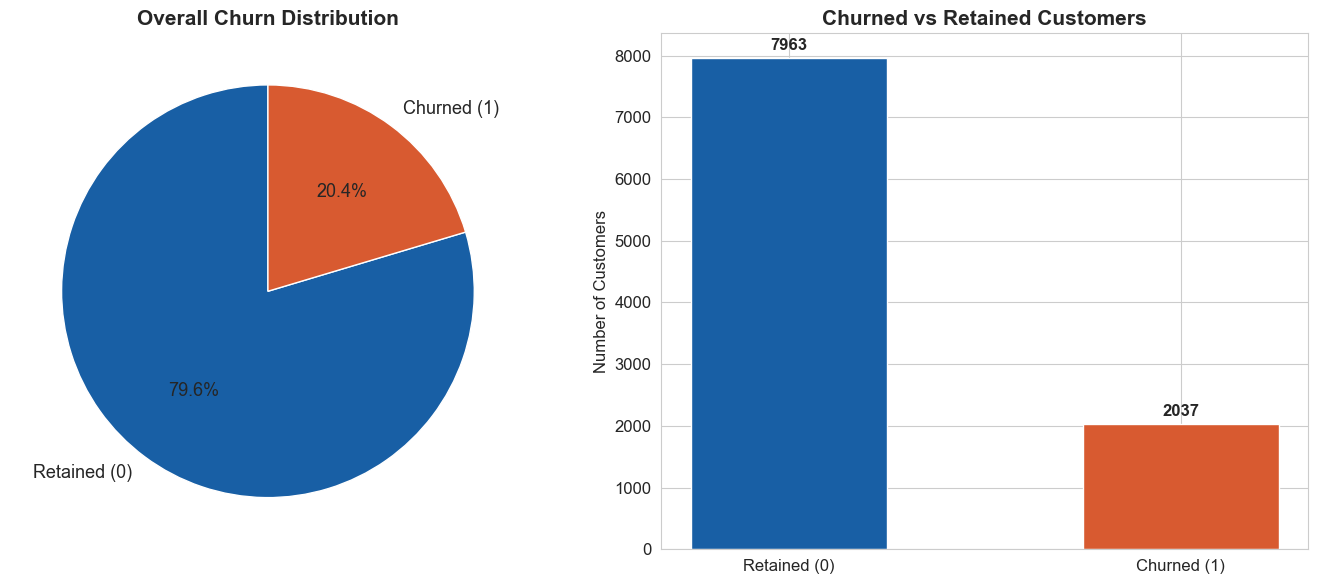


📌 Insight: Overall churn rate is 20.4%
   This means ~1 in 5 customers are leaving the bank.


In [6]:
# ── Chart 1: Overall Churn Rate ───────────────────────────────────
churn_counts = df['Exited'].value_counts()
churn_labels = ['Retained (0)', 'Churned (1)']
churn_colors = ['#185FA5', '#D85A30']

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Pie chart
axes[0].pie(
    churn_counts,
    labels   = churn_labels,
    colors   = churn_colors,
    autopct  = '%1.1f%%',
    startangle = 90,
    textprops  = {'fontsize': 13}
)
axes[0].set_title('Overall Churn Distribution', fontsize=15, fontweight='bold')

# Bar chart
bars = axes[1].bar(churn_labels, churn_counts, color=churn_colors, width=0.5, edgecolor='white')
axes[1].set_title('Churned vs Retained Customers', fontsize=15, fontweight='bold')
axes[1].set_ylabel('Number of Customers')
for bar, count in zip(bars, churn_counts):
    axes[1].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 80,
                 str(count), ha='center', va='bottom',
                 fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('../reports/figures/01_overall_churn.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\n📌 Insight: Overall churn rate is {df['Exited'].mean():.1%}")
print(f"   This means ~1 in 5 customers are leaving the bank.")


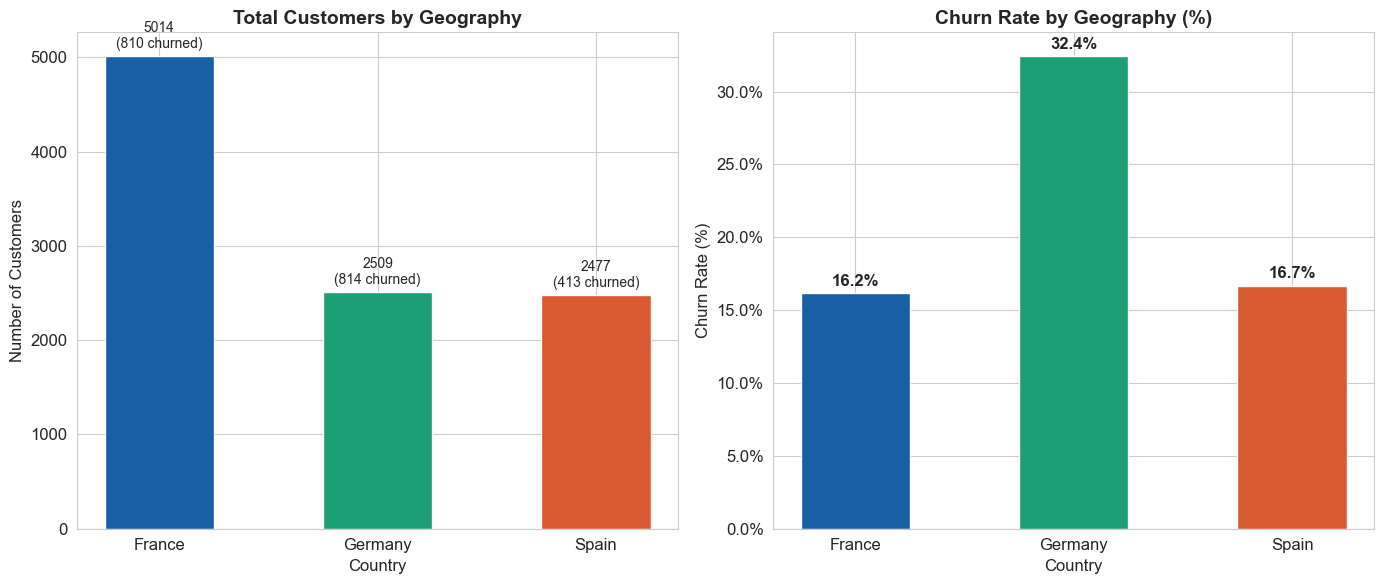


📌 Geography Churn Summary:
Geography  Total  Churned  ChurnRate_pct
   France   5014      810      16.154767
  Germany   2509      814      32.443204
    Spain   2477      413      16.673395


In [7]:
# ── Chart 2: Geography-wise Churn ────────────────────────────────
geo_churn = df.groupby('Geography')['Exited'].agg(['sum', 'count', 'mean']).reset_index()
geo_churn.columns = ['Geography', 'Churned', 'Total', 'ChurnRate']
geo_churn['ChurnRate_pct'] = geo_churn['ChurnRate'] * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Total customers by geography
colors_geo = ['#185FA5', '#1D9E75', '#D85A30']
bars = axes[0].bar(geo_churn['Geography'], geo_churn['Total'],
                   color=colors_geo, edgecolor='white', width=0.5)
axes[0].set_title('Total Customers by Geography', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Number of Customers')
axes[0].set_xlabel('Country')
for bar, row in zip(bars, geo_churn.itertuples()):
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 50,
                 f"{row.Total}\n({row.Churned} churned)",
                 ha='center', va='bottom', fontsize=10)

# Churn rate by geography
bars2 = axes[1].bar(geo_churn['Geography'], geo_churn['ChurnRate_pct'],
                    color=colors_geo, edgecolor='white', width=0.5)
axes[1].set_title('Churn Rate by Geography (%)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Churn Rate (%)')
axes[1].set_xlabel('Country')
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter())
for bar, val in zip(bars2, geo_churn['ChurnRate_pct']):
    axes[1].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.3,
                 f"{val:.1f}%", ha='center', va='bottom',
                 fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('../reports/figures/02_geography_churn.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n📌 Geography Churn Summary:")
print(geo_churn[['Geography', 'Total', 'Churned', 'ChurnRate_pct']].to_string(index=False))

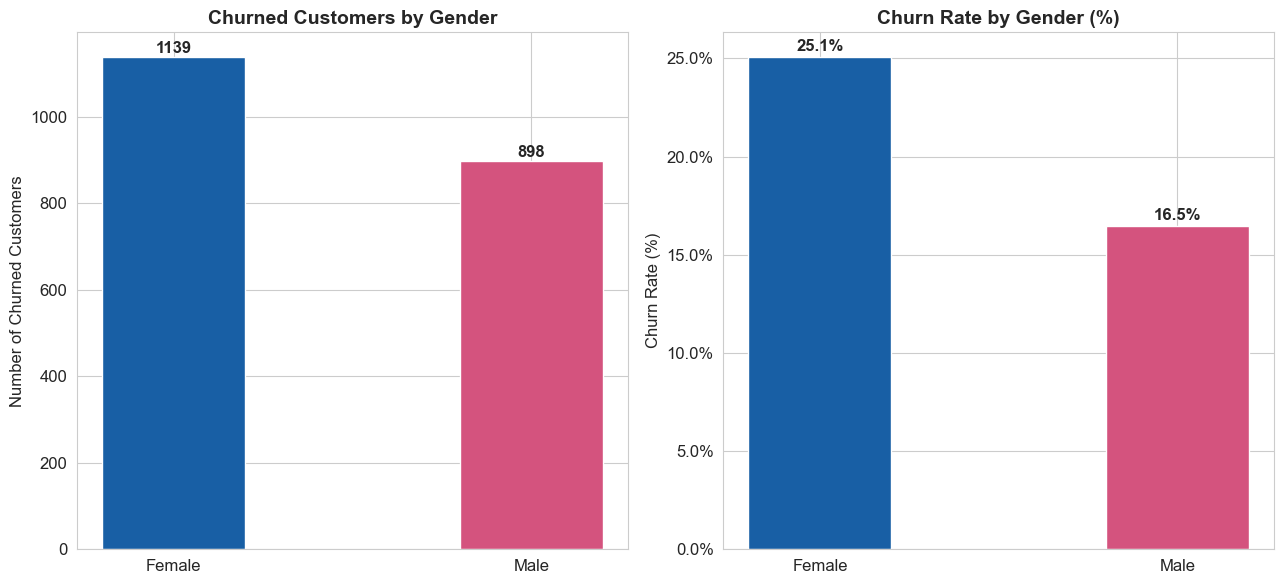


📌 Gender Churn Summary:
Gender  Churned  Total  ChurnRate
Female     1139   4543   0.250715
  Male      898   5457   0.164559


In [8]:
# ── Chart 3: Gender-wise Churn ────────────────────────────────────
gender_churn = df.groupby('Gender')['Exited'].agg(['sum','count','mean']).reset_index()
gender_churn.columns = ['Gender', 'Churned', 'Total', 'ChurnRate']

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

colors_g = ['#185FA5', '#D4537E']

# Count
axes[0].bar(gender_churn['Gender'], gender_churn['Churned'],
            color=colors_g, width=0.4, edgecolor='white')
axes[0].set_title('Churned Customers by Gender', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Number of Churned Customers')
for i, row in gender_churn.iterrows():
    axes[0].text(i, row['Churned'] + 10, str(row['Churned']),
                 ha='center', fontsize=12, fontweight='bold')

# Rate
axes[1].bar(gender_churn['Gender'], gender_churn['ChurnRate']*100,
            color=colors_g, width=0.4, edgecolor='white')
axes[1].set_title('Churn Rate by Gender (%)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Churn Rate (%)')
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter())
for i, row in gender_churn.iterrows():
    axes[1].text(i, row['ChurnRate']*100 + 0.3,
                 f"{row['ChurnRate']*100:.1f}%",
                 ha='center', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('../reports/figures/03_gender_churn.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n📌 Gender Churn Summary:")
print(gender_churn.to_string(index=False))

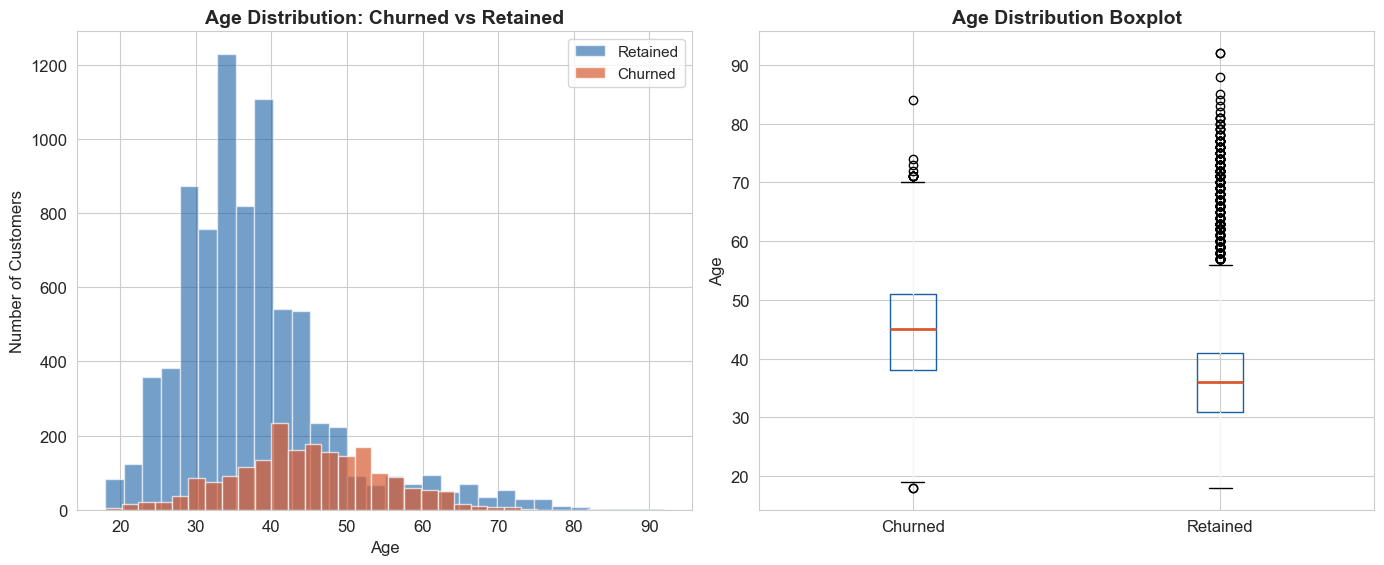


📌 Insight: Churned customers avg age  = 44.8 years
            Retained customers avg age = 37.4 years
   Older customers tend to churn more.


In [9]:
# ── Chart 4: Age Distribution — Churned vs Retained ───────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

churned  = df[df['Exited'] == 1]['Age']
retained = df[df['Exited'] == 0]['Age']

# Histogram overlay
axes[0].hist(retained, bins=30, alpha=0.6, color='#185FA5', label='Retained', edgecolor='white')
axes[0].hist(churned,  bins=30, alpha=0.7, color='#D85A30', label='Churned',  edgecolor='white')
axes[0].set_title('Age Distribution: Churned vs Retained', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Number of Customers')
axes[0].legend(fontsize=11)

# Box plot
df['Churn_Label'] = df['Exited'].map({0: 'Retained', 1: 'Churned'})
df.boxplot(column='Age', by='Churn_Label', ax=axes[1],
           boxprops=dict(color='#185FA5'),
           medianprops=dict(color='#D85A30', linewidth=2))
axes[1].set_title('Age Distribution Boxplot', fontsize=14, fontweight='bold')
axes[1].set_xlabel('')
axes[1].set_ylabel('Age')
plt.suptitle('')

plt.tight_layout()
plt.savefig('../reports/figures/04_age_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\n📌 Insight: Churned customers avg age  = {churned.mean():.1f} years")
print(f"            Retained customers avg age = {retained.mean():.1f} years")
print(f"   Older customers tend to churn more.")

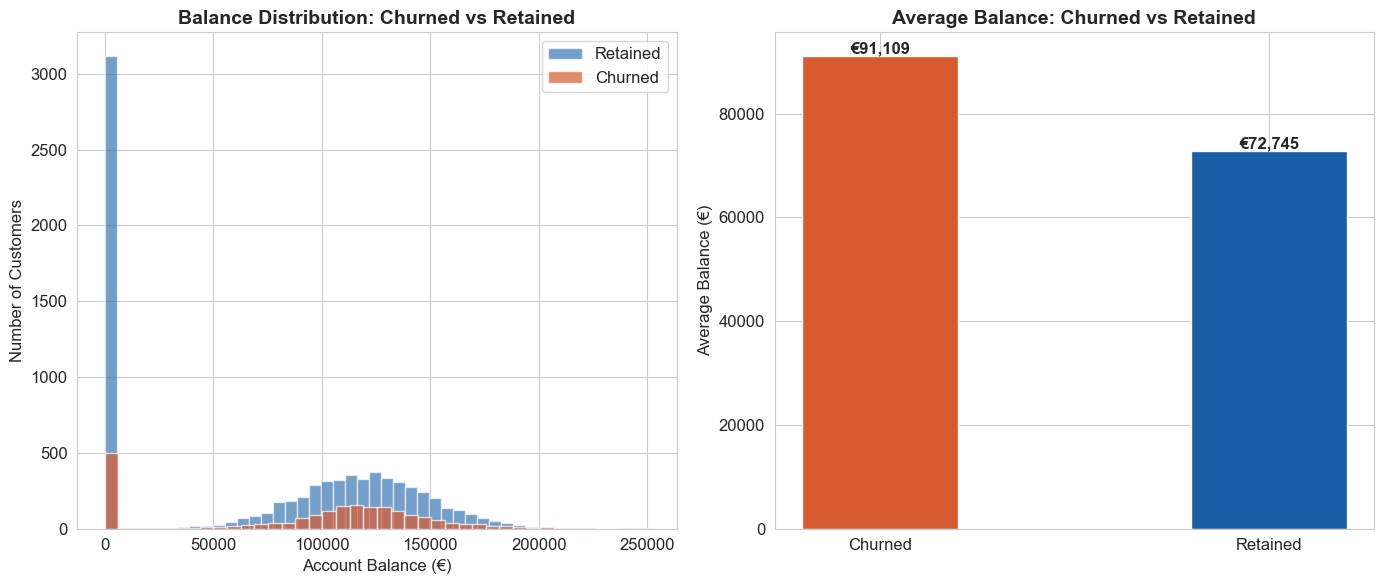


📌 Insight: Churned customers avg balance  = €91,109
            Retained customers avg balance = €72,745


In [10]:
# ── Chart 5: Balance Distribution ────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

bal_churned  = df[df['Exited'] == 1]['Balance']
bal_retained = df[df['Exited'] == 0]['Balance']

axes[0].hist(bal_retained, bins=40, alpha=0.6, color='#185FA5',
             label='Retained', edgecolor='white')
axes[0].hist(bal_churned,  bins=40, alpha=0.7, color='#D85A30',
             label='Churned', edgecolor='white')
axes[0].set_title('Balance Distribution: Churned vs Retained', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Account Balance (€)')
axes[0].set_ylabel('Number of Customers')
axes[0].legend()

# Mean balance comparison
mean_bal = df.groupby('Churn_Label')['Balance'].mean()
axes[1].bar(mean_bal.index, mean_bal.values,
            color=['#D85A30', '#185FA5'], width=0.4, edgecolor='white')
axes[1].set_title('Average Balance: Churned vs Retained', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Average Balance (€)')
for i, (label, val) in enumerate(mean_bal.items()):
    axes[1].text(i, val + 500, f"€{val:,.0f}",
                 ha='center', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('../reports/figures/05_balance_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\n📌 Insight: Churned customers avg balance  = €{bal_churned.mean():,.0f}")
print(f"            Retained customers avg balance = €{bal_retained.mean():,.0f}")

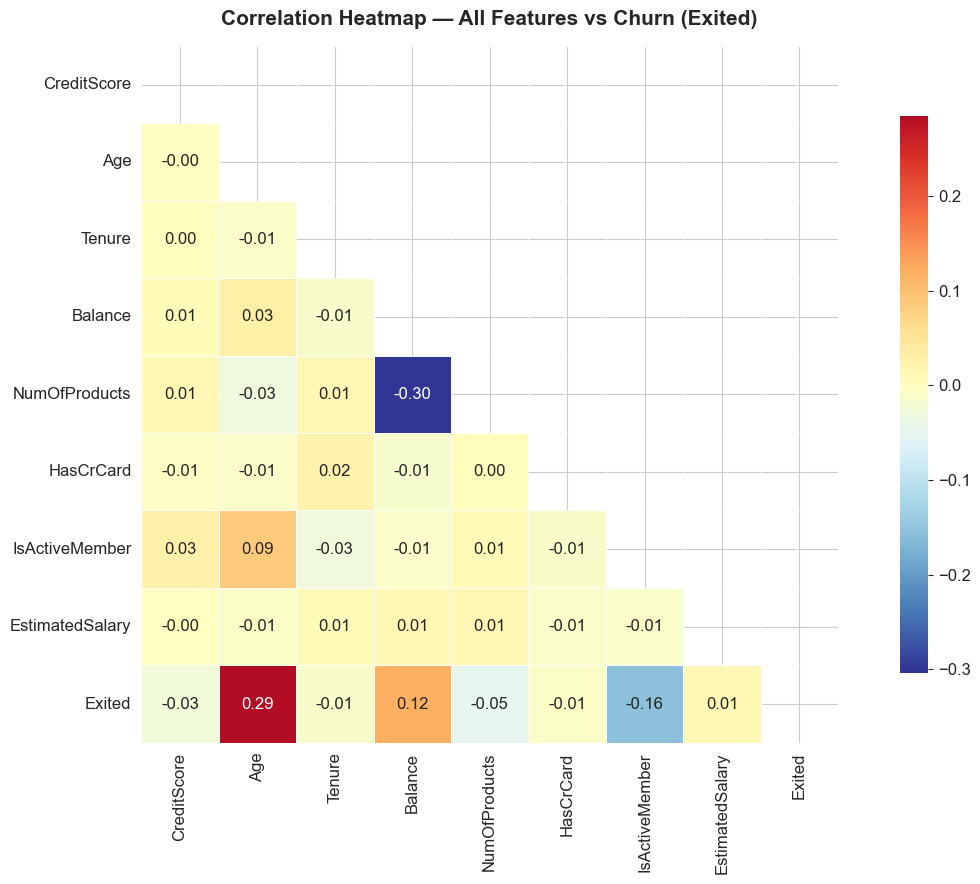


📌 Top Features Correlated with Churn (Exited):
Exited             1.000000
Age                0.285323
Balance            0.118533
EstimatedSalary    0.012097
HasCrCard         -0.007138
Tenure            -0.014001
CreditScore       -0.027094
NumOfProducts     -0.047820
IsActiveMember    -0.156128


In [11]:
# ── Chart 6: Correlation Heatmap ─────────────────────────────────
# Select numeric columns only
numeric_df = df.select_dtypes(include=[np.number]).drop(columns=['Exited'])

corr_with_churn = df[numeric_df.columns.tolist() + ['Exited']].corr()

plt.figure(figsize=(13, 9))
mask = np.zeros_like(corr_with_churn, dtype=bool)
mask[np.triu_indices_from(mask)] = True   # Show only lower triangle

sns.heatmap(
    corr_with_churn,
    mask      = mask,
    annot     = True,
    fmt       = '.2f',
    cmap      = 'RdYlBu_r',
    center    = 0,
    linewidths= 0.5,
    square    = True,
    cbar_kws  = {'shrink': 0.8}
)
plt.title('Correlation Heatmap — All Features vs Churn (Exited)',
          fontsize=15, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig('../reports/figures/06_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

# Show top correlations with Exited
print("\n📌 Top Features Correlated with Churn (Exited):")
print(corr_with_churn['Exited'].sort_values(ascending=False).to_string())

In [12]:
# ── DAY 3: Create Segmentation Columns ───────────────────────────

# 1. Age Segment
df['age_segment'] = pd.cut(
    df['Age'],
    bins   = [0, 30, 45, 60, 100],
    labels = ['Under 30', '30-45', '46-60', 'Over 60']
)

# 2. Credit Score Band
df['credit_band'] = pd.cut(
    df['CreditScore'],
    bins   = [0, 580, 720, 850],
    labels = ['Low', 'Medium', 'High']
)

# 3. Tenure Group
df['tenure_group'] = pd.cut(
    df['Tenure'],
    bins   = [-1, 2, 6, 10],
    labels = ['New (0-2 yrs)', 'Mid-term (3-6 yrs)', 'Long-term (7+ yrs)']
)

# 4. Balance Segment
median_bal = df['Balance'].median()
df['balance_segment'] = df['Balance'].apply(
    lambda x: 'Zero Balance'  if x == 0
    else ('Low Balance'  if x < median_bal
    else  'High Balance')
)

# 5. Products Segment
df['products_segment'] = df['NumOfProducts'].apply(
    lambda x: '1 Product'    if x == 1
    else ('2 Products'   if x == 2
    else  '3+ Products')
)

print("✅ All segmentation columns created!")
print("\nNew columns added:")
new_cols = ['age_segment', 'credit_band', 'tenure_group',
            'balance_segment', 'products_segment']
for col in new_cols:
    print(f"  {col}: {df[col].unique().tolist()}")

✅ All segmentation columns created!

New columns added:
  age_segment: ['30-45', '46-60', 'Under 30', 'Over 60']
  credit_band: ['Medium', 'Low', 'High']
  tenure_group: ['New (0-2 yrs)', 'Long-term (7+ yrs)', 'Mid-term (3-6 yrs)']
  balance_segment: ['Zero Balance', 'Low Balance', 'High Balance']
  products_segment: ['1 Product', '3+ Products', '2 Products']


In [13]:
# ── Preview all segments ──────────────────────────────────────────
print("📊 Segment Distribution Summary:\n")

for col in ['age_segment', 'credit_band', 'tenure_group',
            'balance_segment', 'products_segment']:
    print(f"── {col} ──")
    print(df[col].value_counts().to_string())
    print()

📊 Segment Distribution Summary:

── age_segment ──
age_segment
30-45       5921
Under 30    1968
46-60       1647
Over 60      464

── credit_band ──
credit_band
Medium    5199
High      2408
Low       2393

── tenure_group ──
tenure_group
Mid-term (3-6 yrs)    3977
Long-term (7+ yrs)    3527
New (0-2 yrs)         2496

── balance_segment ──
balance_segment
High Balance    5000
Zero Balance    3617
Low Balance     1383

── products_segment ──
products_segment
1 Product      5084
2 Products     4590
3+ Products     326



In [14]:
# ── Save Segmented Dataset ────────────────────────────────────────
save_path = '../data/processed/churn_segmented.csv'
df.drop(columns=['Churn_Label'], inplace=True)   # cleanup temp column
df.to_csv(save_path, index=False)

print(f"✅ Segmented dataset saved!")
print(f"   Path    : {save_path}")
print(f"   Shape   : {df.shape}")
print(f"   Columns : {df.columns.tolist()}")

✅ Segmented dataset saved!
   Path    : ../data/processed/churn_segmented.csv
   Shape   : (10000, 16)
   Columns : ['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited', 'age_segment', 'credit_band', 'tenure_group', 'balance_segment', 'products_segment']


## Key Exploratory Insights & Next Steps

1. **Geographic Divergence**: Germany exhibits a churn rate of ~32.4%, significantly higher than France (~16.2%) and Spain (~16.7%).
2. **Demographic Susceptibility**: Customers aged 46-60 face the highest attrition rates (>50%), pointing towards mid-career financial migration or dissatisfaction.
3. **Product Complexity**: Customers with 3 or 4 bank products churn at an alarming rate (>80%), indicating potential product bundling friction.
4. **Financial Exposure**: High account balance customers churn with substantial capital, creating high revenue-at-risk for the bank.

**Next Stage**: Proceed to Notebook 02 for advanced segmentation, financial scoring, and KPI quantification.